# Copula-based pairs trading on gold and silver: dependence analysis and backtest results

Adapts the copula pairs-trading framework of Krauss & Stübinger (2015) to GLD/SLV, with three
robustness pairs. All results are read from `data/pairs.sqlite`, produced by
`python -m scripts.run_experiments`. Figures are saved to `reports/figures/`.

**Research use only, not investment advice.** Backtests on historical data do not predict future returns.

| | Source |
|---|---|
| t-copula, conditional-probability signals (α = 5%), quantile TP/SL exit, 50 bps cost | Paper (cited) |
| GLD/SLV + 3 pairs, free data 2006–2025, monthly walk-forward refit, z-score baseline | This project |
| Gaussian vs t out-of-sample comparison, tail calibration, cost sensitivity | This project (extension) |

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cpt import analysis, copula, plots
from cpt.backtest import copula_frame
from cpt.config import db_path, load_config
from cpt.db import connect, load_adj_close

cfg = load_config()
s = {**cfg["strategy"], "paper_quantile": cfg["paper_quantile"]}
conn = connect(db_path(cfg))
plots.set_style()
pd.set_option("display.float_format", "{:.4f}".format)

PAIRS = [cfg["pairs"]["main"], *cfg["pairs"]["robustness"]]
PAIR_NAMES = [f"{a}-{b}" for a, b in PAIRS]
MAIN = PAIR_NAMES[0]
SPEC_NAMES = {
    "copula|t|probability": "Copula t (main)",
    "copula|gaussian|probability": "Copula Gaussian",
    "copula|t|paper_quantile": "Copula t, paper exit",
    "zscore|None|None": "z-score baseline",
}

## 1. Data

Adjusted closes from yfinance, inner-joined on common trading days. The first 12 months of each
pair are used only for estimation, so trading starts 2007-06 (GDX-GDXJ: 2010-12).

In [2]:
prices = {name: load_adj_close(conn, list(p)) for name, p in zip(PAIR_NAMES, PAIRS)}
pd.DataFrame({n: {"start": p.index.min().date(), "end": p.index.max().date(), "days": len(p)}
              for n, p in prices.items()}).T

,start,end,days
GLD-SLV,2006-05-01,2025-12-31,4950
GDX-GDXJ,2009-11-11,2025-12-31,4059
XOM-CVX,2006-05-01,2025-12-31,4950
KO-PEP,2006-05-01,2025-12-31,4950


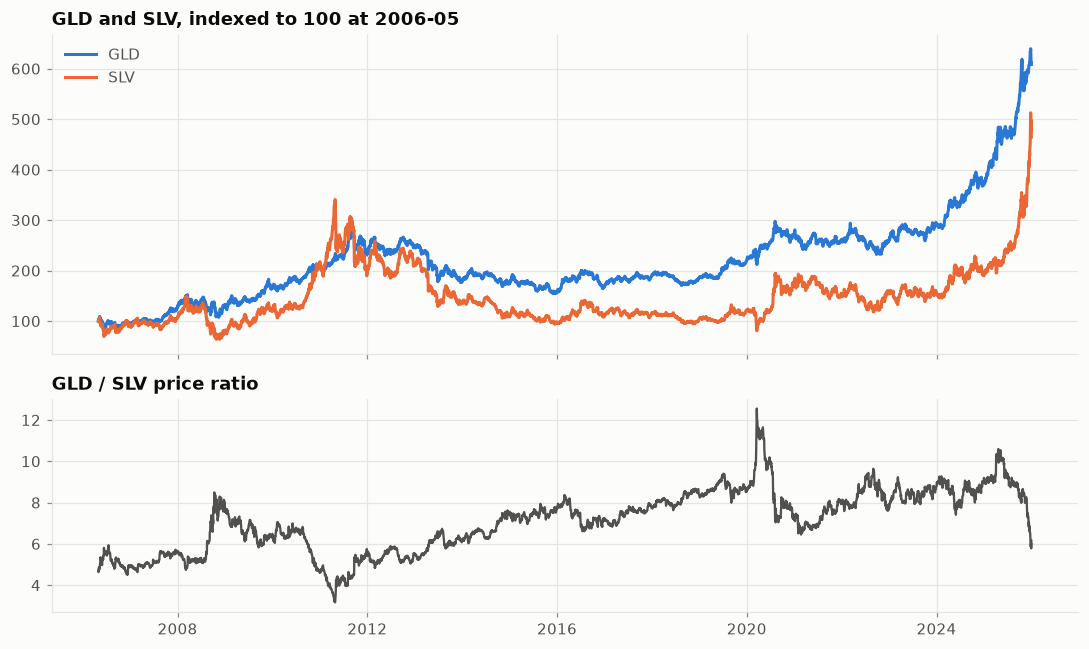

In [3]:
fig = plots.prices_and_ratio(prices[MAIN])
plots.save(fig, "01_prices_and_ratio");

## 2. RQ1: Is there dependence that Pearson correlation misses?

Full-sample daily log returns. `pearson_implied_by_kendall` = sin(πτ/2) is the linear correlation an
elliptical copula would imply from Kendall's τ; a gap to Pearson points to nonlinearity or outliers.
Joint-tail columns: share of days on which both legs are below (above) their own 5% (95%) quantile;
under independence this would be 0.25%.

In [4]:
dep = pd.DataFrame({n: analysis.dependence_summary(np.log(p).diff()) for n, p in prices.items()}).T
dep

,n,pearson,spearman,kendall,pearson_implied_by_kendall,joint_lower_tail,joint_upper_tail,independence_tail
GLD-SLV,4949.0000,0.7925,0.7910,0.6059,0.8144,0.0275,0.0232,0.0025
GDX-GDXJ,4058.0000,0.9504,0.9496,0.8132,0.9573,0.0360,0.0377,0.0025
XOM-CVX,4949.0000,0.8562,0.8267,0.6496,0.8523,0.0313,0.0309,0.0025
KO-PEP,4949.0000,0.6961,0.6586,0.4869,0.6924,0.0240,0.0218,0.0025


## 3. RQ2: Does the t-copula fit better than the Gaussian copula?

Each month both copulas are fit on the previous 12 months and evaluated on the next month
(out-of-sample log-likelihood, using the training ECDF for the new month's returns).

In [5]:
frames, fits = {}, {}
for name in PAIR_NAMES:
    frames[name], fits[name] = copula_frame(prices[name], s, "t", "probability")
pd.DataFrame({n: analysis.fit_comparison(f) for n, f in fits.items()}).T

,months,t_better_aic_share,t_better_oos_share,oos_loglik_diff_total,median_nu,median_tail_dep
GLD-SLV,223.0000,0.5919,0.5650,88.7516,9.7750,0.3175
GDX-GDXJ,181.0000,0.6243,0.5746,52.3384,8.6315,0.6366
XOM-CVX,223.0000,0.9821,0.6906,247.1248,4.1240,0.5339
KO-PEP,223.0000,0.8161,0.6861,139.3907,5.2706,0.3380


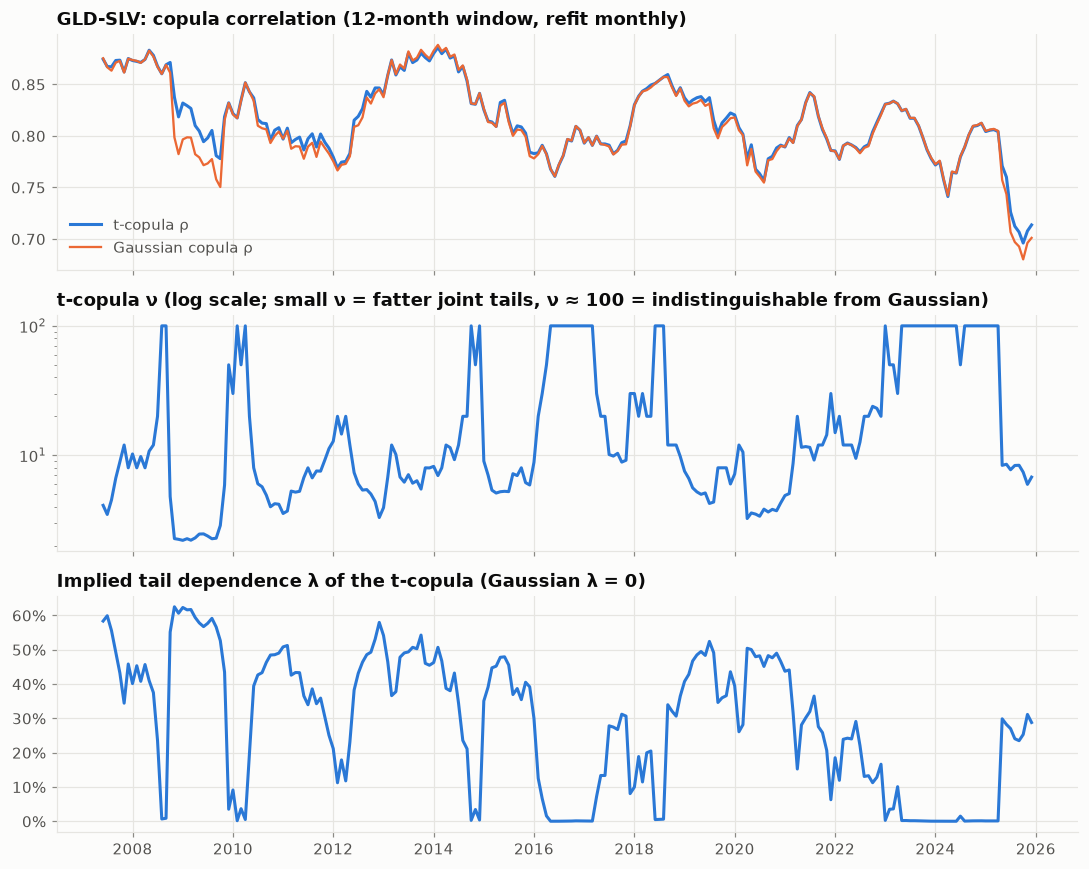

In [6]:
fig = plots.rolling_parameters(fits[MAIN], MAIN)
plots.save(fig, "03_rolling_copula_parameters");

**Out-of-sample tail calibration.** For each month the fitted copulas predict how many days both legs
fall beyond their 5% tails, C(q, q) × days. Summed over all months and compared with what happened.
Both copulas are symmetric, so they predict the same count for the lower and upper tails.

In [7]:
Q = 0.05
calib = pd.DataFrame({n: analysis.oos_tail_calibration(fits[n], frames[n], Q).drop(columns="month").sum()
                      for n in PAIR_NAMES}).T
calib_share = calib.drop(columns="days").div(calib["days"], axis=0)
calib_share

,observed_lower,observed_upper,pred_gaussian,pred_t
GLD-SLV,0.0297,0.0239,0.0256,0.0275
GDX-GDXJ,0.0424,0.0398,0.0380,0.0389
XOM-CVX,0.0325,0.0297,0.0267,0.0305
KO-PEP,0.0289,0.0216,0.0196,0.0232


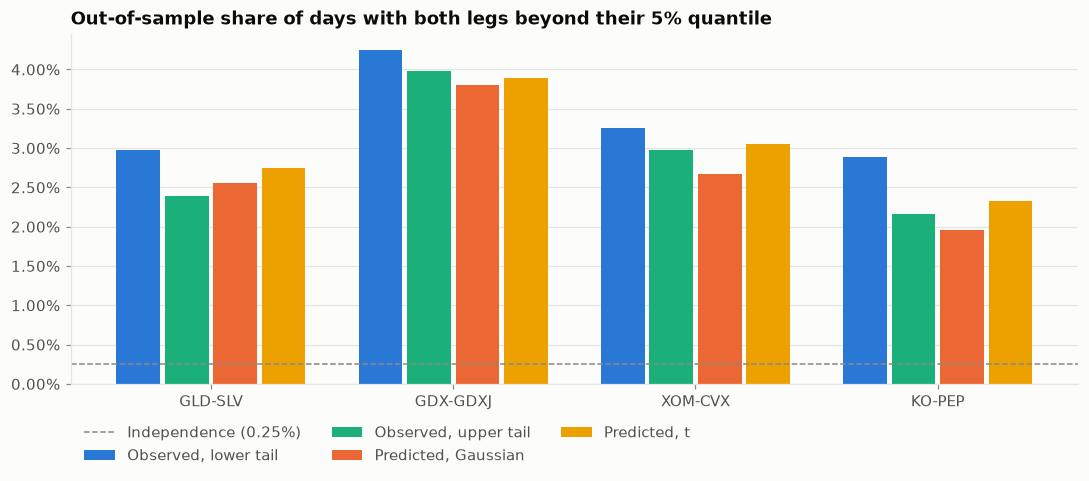

In [8]:
fig = plots.tail_calibration(calib, Q)
plots.save(fig, "04_tail_calibration");

**Signal regions for one window.** Latest month in the sample: grey points are the 12-month estimation
window, black points the out-of-sample month. Shaded areas are regions A and B where trades open.

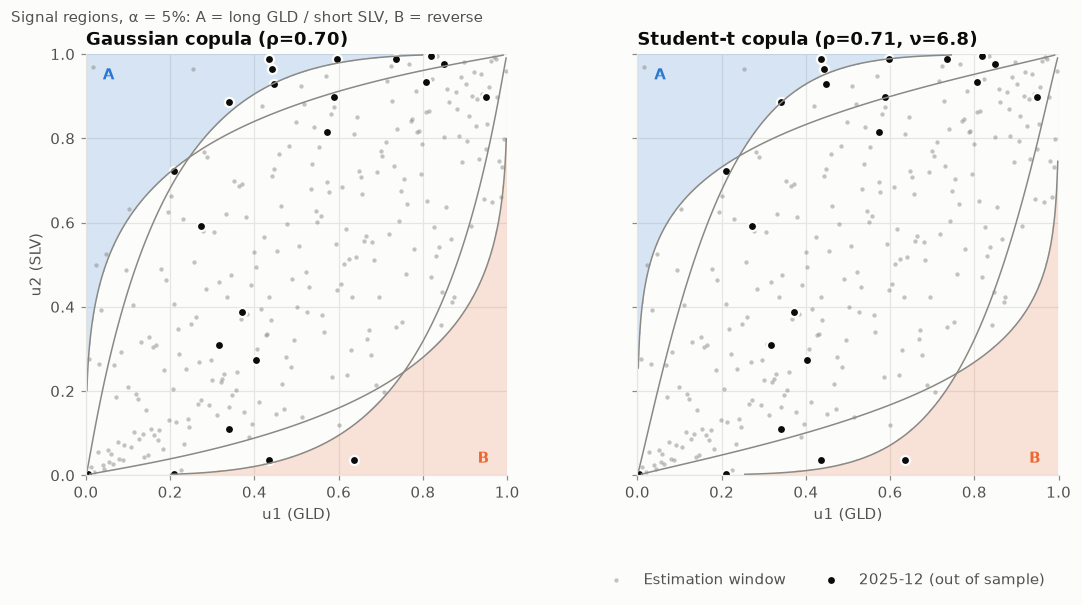

In [9]:
r = np.log(prices[MAIN]).diff().dropna()
month = r.index.to_period("M")
last = month.max()
first = int(np.argmax(month == last))
train, test = r.iloc[first - s["estimation_window_days"]:first], r[month == last]
tr = [train.iloc[:, i].to_numpy() for i in range(2)]
train_u = tuple(copula.pseudo_observations(x) for x in tr)
test_u = tuple(copula.ecdf_transform(tr[i], test.iloc[:, i].to_numpy()) for i in range(2))
fig = plots.copula_bands(train_u, test_u, copula.fit_gaussian(*train_u), copula.fit_t(*train_u),
                         s["alpha"], tuple(cfg["pairs"]["main"]), str(last))
plots.save(fig, "02_copula_signal_regions");

## 4. RQ3–RQ5: Strategy results

Main specification: t-copula, probability exit, one-day execution lag, 50 bps round-trip cost per pair
trade. Other specifications were registered in `config.yaml` before their results were seen.
`breakeven_bps` is the average gross return per trade, i.e. the round-trip cost at which the average
trade nets zero.

In [10]:
runs = pd.read_sql("SELECT * FROM experiment_runs", conn)
metrics = pd.read_sql("SELECT * FROM run_metrics", conn).pivot(index="run_id", columns="metric", values="value")
runs = runs.join(metrics, on="run_id")
runs["spec"] = (runs["model"] + "|" + runs["family"].fillna("None") + "|" + runs["exit_rule"].fillna("None")).map(SPEC_NAMES)
runs.loc[runs["model"] == "buy_hold", "spec"] = runs["family"]

cols = ["ann_return", "ann_vol", "sharpe", "sortino", "max_drawdown", "var_95", "cvar_95",
        "n_trades", "avg_holding_days", "win_rate", "breakeven_bps"]
main_table = runs[(runs["pair"] == MAIN) & runs["cost_bps"].isin([0, 50])]
main_table.set_index(["spec", "cost_bps"])[cols].sort_index()

ann_return  ann_vol  sharpe  sortino  \
spec                 cost_bps                                         
50/50 GLD+SLV        0.0000        0.1009   0.2308  0.4709   0.6582   
Copula Gaussian      0.0000       -0.0236   0.0934 -0.3603  -0.4802   
                     50.0000      -0.0841   0.0947 -1.0296  -1.3211   
Copula t (main)      0.0000       -0.0241   0.0925 -0.3711  -0.4941   
                     50.0000      -0.0794   0.0937 -0.9867  -1.2668   
Copula t, paper exit 0.0000       -0.0525   0.1147 -0.5365  -0.7016   
                     50.0000      -0.0950   0.1153 -0.9313  -1.1951   
GLD                  0.0000        0.1018   0.1751  0.5603   0.7967   
SPY                  0.0000        0.1043   0.1991  0.5264   0.7409   
z-score baseline     0.0000        0.0080   0.1469  0.0314   0.0427   
                     50.0000      -0.0194   0.1471 -0.1555  -0.2101   

                               max_drawdown  var_95  cvar_95  n_trades  \
spec                 cost_bps                                            
50/50 GLD+SLV        0.0000          0.5844 -0.0222  -0.0344       NaN   
Copula Gaussian      0.0000          0.4858 -0.0021  -0.0132  237.0000   
                     50.0000         0.8045 -0.0032  -0.0143  237.0000   
Copula t (main)      0.0000          0.4729 -0.0011  -0.0127  216.0000   
                     50.0000         0.7847 -0.0029  -0.0138  216.0000   
Copula t, paper exit 0.0000          0.6989 -0.0090  -0.0191  170.0000   
                     50.0000         0.8553 -0.0093  -0.0195  170.0000   
GLD                  0.0000          0.4556 -0.0173  -0.0258       NaN   
SPY                  0.0000          0.5519 -0.0186  -0.0306       NaN   
z-score baseline     0.0000          0.4356 -0.0114  -0.0237  102.0000   
                     50.0000         0.5687 -0.0114  -0.0239  102.0000   

                               avg_holding_days  win_rate  breakeven_bps  
spec                 cost_bps                                             
50/50 GLD+SLV        0.0000                 NaN       NaN            NaN  
Copula Gaussian      0.0000              2.3122    0.4726       -15.2350  
                     50.0000             2.3122    0.3418       -15.2350  
Copula t (main)      0.0000              2.3148    0.4583       -17.2777  
                     50.0000             2.3148    0.3380       -17.2777  
Copula t, paper exit 0.0000              8.0059    0.4235       -51.6619  
                     50.0000             8.0059    0.3882       -51.6619  
GLD                  0.0000                 NaN       NaN            NaN  
SPY                  0.0000                 NaN       NaN            NaN  
z-score baseline     0.0000             16.8235    0.5392        34.2594  
                     50.0000            16.8235    0.5196        34.2594

In [11]:
net = runs[(runs["cost_bps"] == 50) & (runs["model"] != "buy_hold")]
net.pivot(index="pair", columns="spec", values="sharpe").loc[PAIR_NAMES]

spec,Copula Gaussian,Copula t (main),"Copula t, paper exit",z-score baseline
pair,,,,
GLD-SLV,-1.0296,-0.9867,-0.9313,-0.1555
GDX-GDXJ,-1.8216,-1.7659,-0.8763,0.0094
XOM-CVX,-1.2360,-1.1512,-0.9823,0.1301
KO-PEP,-0.8545,-0.7911,-0.4113,-0.1309


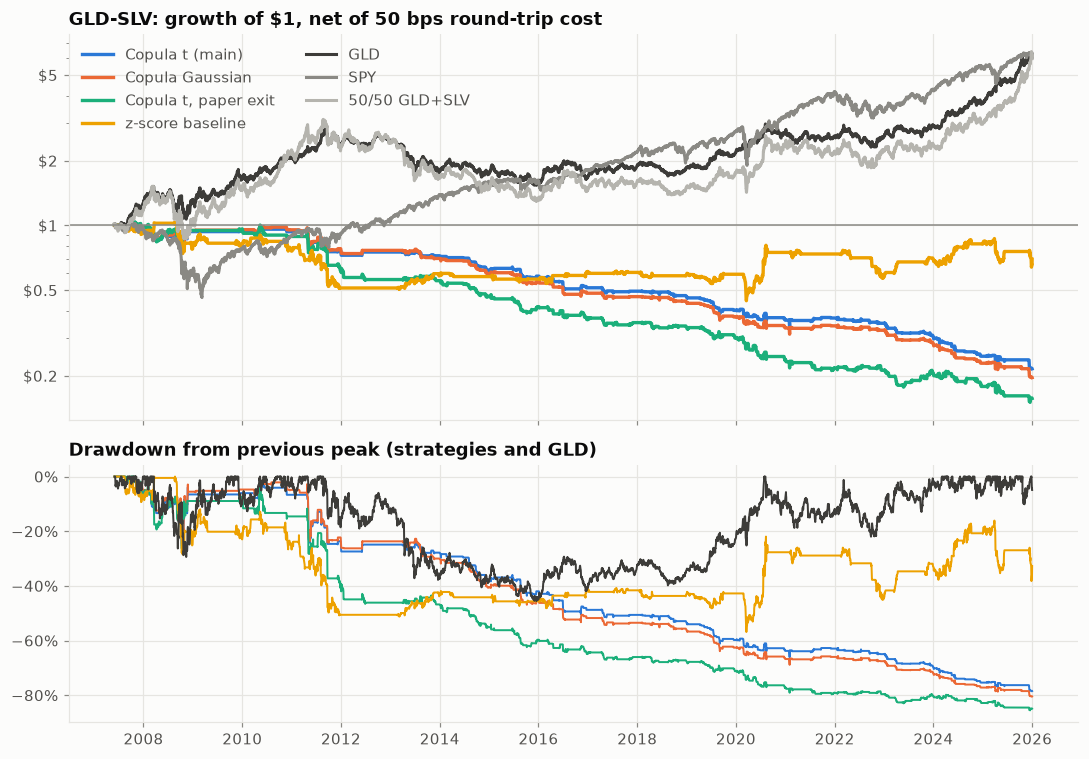

In [12]:
def load_returns(run_id):
    q = "SELECT date, ret FROM strategy_returns WHERE run_id = ? ORDER BY date"
    return pd.read_sql(q, conn, params=[run_id], parse_dates=["date"]).set_index("date")["ret"]

strategy_ids = {name: f"{MAIN}|{key}|50" for key, name in SPEC_NAMES.items()}
bench_ids = {b: f"{MAIN}|buy_hold|{b}" for b in ["GLD", "SPY", "50/50 GLD+SLV"]}
returns = {name: load_returns(rid) for name, rid in {**strategy_ids, **bench_ids}.items()}

fig = plots.equity_and_drawdown(returns, f"{MAIN}: growth of $1, net of 50 bps round-trip cost")
plots.save(fig, "05_equity_and_drawdown");

cost_bps,0.0000,10.0000,25.0000,50.0000,100.0000
spec,,,,,
Copula t (main),-0.0241,-0.0354,-0.0522,-0.0794,-0.1317
Copula Gaussian,-0.0236,-0.0360,-0.0543,-0.0841,-0.1410
"Copula t, paper exit",-0.0525,-0.0612,-0.0740,-0.0950,-0.1357
z-score baseline,0.0080,0.0025,-0.0058,-0.0194,-0.0460


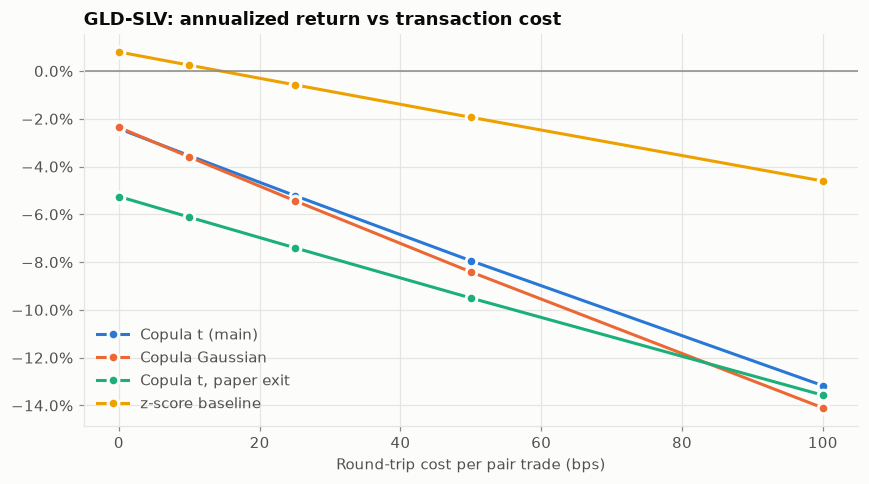

In [13]:
cost_table = (runs[(runs["pair"] == MAIN) & (runs["model"] != "buy_hold")]
              .pivot(index="spec", columns="cost_bps", values="ann_return")
              .loc[list(SPEC_NAMES.values())])
fig = plots.cost_sensitivity(cost_table, MAIN)
plots.save(fig, "06_cost_sensitivity")
cost_table

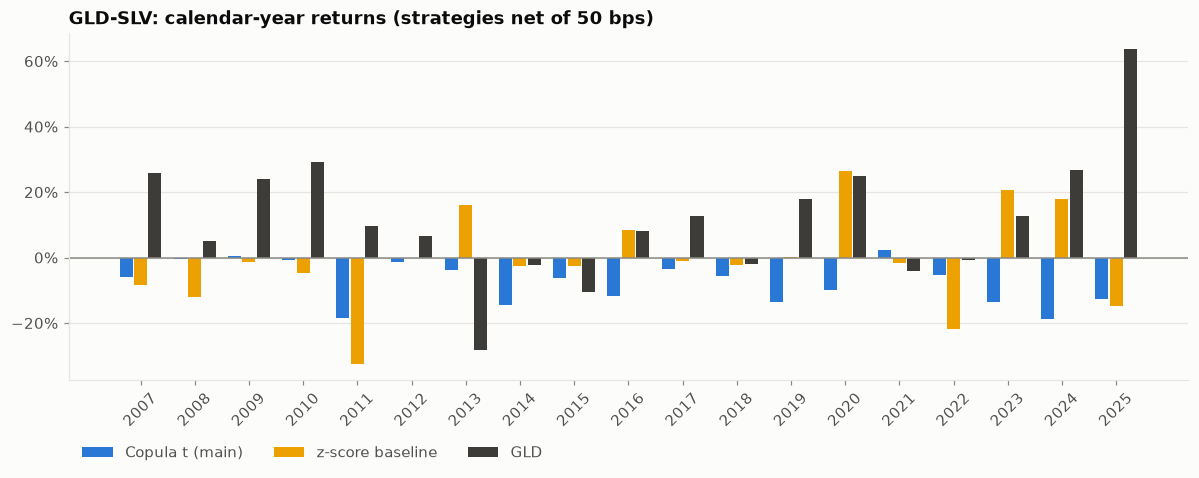

In [14]:
subset = {k: returns[k] for k in ["Copula t (main)", "z-score baseline", "GLD"]}
fig = plots.annual_returns(subset, f"{MAIN}: calendar-year returns (strategies net of 50 bps)")
plots.save(fig, "07_annual_returns");

exit_reason,reversion,take_profit,stop_loss,max_holding,end_of_data
Copula t (main),0.9491,0.0000,0.0463,0.0000,0.0046
Copula Gaussian,0.9536,0.0000,0.0422,0.0000,0.0042
"Copula t, paper exit",0.0000,0.4000,0.5353,0.0588,0.0059
z-score baseline,0.0980,0.0000,0.2745,0.6176,0.0098


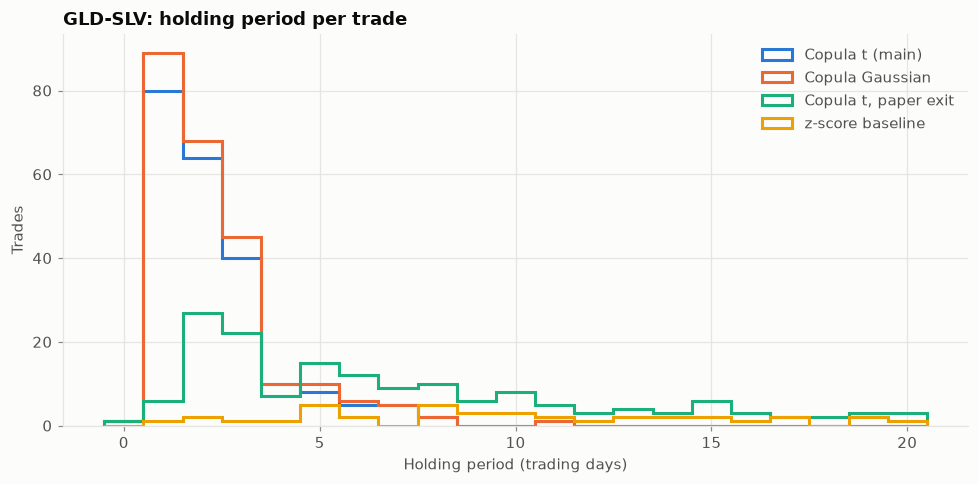

In [15]:
trades = {name: pd.read_sql("SELECT * FROM trades WHERE run_id = ?", conn, params=[rid])
          for name, rid in strategy_ids.items()}
fig = plots.holding_periods(trades, MAIN)
plots.save(fig, "08_holding_periods")
reasons = ["reversion", "take_profit", "stop_loss", "max_holding", "end_of_data"]
pd.DataFrame({n: t["exit_reason"].value_counts(normalize=True) for n, t in trades.items()}).reindex(reasons).fillna(0).T

## 5. Statistical significance

Daily strategy returns are autocorrelated (positions last several days), so plain t-tests overstate
precision. Two checks:

- **Newey-West t-statistic** of the mean daily return (H0: mean = 0), lag length floor(4·(n/100)^(2/9)).
- **Stationary block bootstrap** (mean block 20 days, 2,000 resamples, seed from `config.yaml`) for a 95%
  interval of the annualized Sharpe ratio, and for the annualized return difference between two specs
  on the same days.

The Sharpe here is computed on raw returns (no risk-free rate), so it differs slightly from the tables above.

In [16]:
from cpt import inference

SEED = cfg["seed"]

def test_row(r, **labels):
    nw, ci = inference.newey_west_mean_test(r), inference.bootstrap_ci(r, seed=SEED)
    return {**labels, "ann_mean": nw["mean"] * 252, "t_nw": nw["t_nw"], "p_nw": nw["p_nw"],
            "sharpe": ci["estimate"], "sharpe_ci_low": ci["ci_low"], "sharpe_ci_high": ci["ci_high"]}

rows = [test_row(load_returns(f"{pair}|{key}|{bps}"), pair=pair, spec=name, cost_bps=bps)
        for pair in PAIR_NAMES for key, name in SPEC_NAMES.items() for bps in [0, 50]]
rows.append(test_row(returns["GLD"], pair=MAIN, spec="GLD", cost_bps=0))
significance = pd.DataFrame(rows).set_index(["pair", "spec", "cost_bps"])
significance

ann_mean    t_nw   p_nw  sharpe  \
pair     spec                 cost_bps                                    
GLD-SLV  Copula t (main)      0          -0.0201 -0.9450 0.3447 -0.2174   
                              50         -0.0783 -3.6449 0.0003 -0.8354   
         Copula Gaussian      0          -0.0195 -0.9072 0.3643 -0.2082   
                              50         -0.0833 -3.8514 0.0001 -0.8799   
         Copula t, paper exit 0          -0.0473 -1.8414 0.0656 -0.4126   
                              50         -0.0931 -3.5776 0.0003 -0.8080   
         z-score baseline     0           0.0188  0.5877 0.5567  0.1282   
                              50         -0.0087 -0.2665 0.7899 -0.0588   
GDX-GDXJ Copula t (main)      0          -0.0127 -0.9291 0.3528 -0.2149   
                              50         -0.0937 -6.5018 0.0000 -1.5276   
         Copula Gaussian      0          -0.0162 -1.1835 0.2366 -0.2726   
                              50         -0.0979 -6.7219 0.0000 -1.5850   
         Copula t, paper exit 0          -0.0082 -0.3487 0.7273 -0.0879   
                              50         -0.0680 -2.8484 0.0044 -0.7213   
         z-score baseline     0           0.0384  1.6052 0.1084  0.3997   
                              50          0.0155  0.6450 0.5189  0.1611   
XOM-CVX  Copula t (main)      0           0.0031  0.2328 0.8159  0.0560   
                              50         -0.0508 -3.7314 0.0002 -0.8995   
         Copula Gaussian      0          -0.0048 -0.3245 0.7456 -0.0752   
                              50         -0.0665 -4.3910 0.0000 -1.0185   
         Copula t, paper exit 0          -0.0221 -1.1599 0.2461 -0.2737   
                              50         -0.0657 -3.3947 0.0007 -0.8076   
         z-score baseline     0           0.0494  2.2156 0.0267  0.5019   
                              50          0.0271  1.2125 0.2253  0.2738   
KO-PEP   Copula t (main)      0           0.0118  1.1808 0.2377  0.2493   
                              50         -0.0243 -2.4009 0.0164 -0.4989   
         Copula Gaussian      0           0.0161  1.2900 0.1970  0.2839   
                              50         -0.0354 -2.8291 0.0047 -0.6098   
         Copula t, paper exit 0           0.0201  1.3644 0.1724  0.3076   
                              50         -0.0130 -0.8898 0.3736 -0.1967   
         z-score baseline     0           0.0256  1.3106 0.1900  0.2852   
                              50          0.0024  0.1238 0.9015  0.0271   
GLD-SLV  GLD                  0           0.1123  2.8583 0.0043  0.6414   

                                        sharpe_ci_low  sharpe_ci_high  
pair     spec                 cost_bps                                 
GLD-SLV  Copula t (main)      0               -0.6243          0.1674  
                              50              -1.2800         -0.4447  
         Copula Gaussian      0               -0.6129          0.1740  
                              50              -1.3377         -0.4717  
         Copula t, paper exit 0               -0.8322         -0.0284  
                              50              -1.2226         -0.4233  
         z-score baseline     0               -0.3036          0.5450  
                              50              -0.4982          0.3636  
GDX-GDXJ Copula t (main)      0               -0.6156          0.2032  
                              50              -1.9211         -1.1355  
         Copula Gaussian      0               -0.6716          0.1339  
                              50              -1.9919         -1.1820  
         Copula t, paper exit 0               -0.5734          0.3863  
                              50              -1.1875         -0.2667  
         z-score baseline     0               -0.1306          0.8511  
                              50              -0.3931          0.6296  
XOM-CVX  Copula t (main)      0               -0.3682          0.5363  
                              50              

**Does the t-copula beat the Gaussian copula?** Two separate questions: fit (monthly out-of-sample
log-likelihood difference, Newey-West test on the monthly series, 3 lags) and trading (paired bootstrap
of the daily net return difference, t minus Gaussian, 50 bps).

In [17]:
rows = []
for pair in PAIR_NAMES:
    ll = inference.newey_west_mean_test(fits[pair]["t_oos_loglik"] - fits[pair]["gaussian_oos_loglik"], lags=3)
    diff = inference.paired_bootstrap_difference(
        load_returns(f"{pair}|copula|t|probability|50"), load_returns(f"{pair}|copula|gaussian|probability|50"), seed=SEED)
    rows.append({"pair": pair, "oos_ll_gain_per_month": ll["mean"], "t_nw_ll": ll["t_nw"], "p_nw_ll": ll["p_nw"],
                 "ann_return_diff": diff["estimate"], "diff_ci_low": diff["ci_low"], "diff_ci_high": diff["ci_high"]})
pd.DataFrame(rows).set_index("pair")

,oos_ll_gain_per_month,t_nw_ll,p_nw_ll,ann_return_diff,diff_ci_low,diff_ci_high
pair,,,,,,
GLD-SLV,0.3980,2.1938,0.0283,0.0050,-0.0004,0.0110
GDX-GDXJ,0.2892,3.2937,0.0010,0.0041,-0.0011,0.0095
XOM-CVX,1.1082,5.9106,0.0000,0.0158,0.0006,0.0316
KO-PEP,0.6251,4.0895,0.0000,0.0111,-0.0030,0.0242


## 6. Subperiods

Four stress periods, registered in `config.yaml` before these results were computed and dated by
external events, not by strategy performance: the 2007–09 financial crisis (NBER recession dates), the
2011 silver boom and bust, the 2020 COVID shock, and the 2022 rate-hike cycle. `other` is every trading
day outside them. Returns are total returns over each period (periods are too short to annualize
meaningfully); strategies are net of 50 bps. The chart shows the four stress periods only; `other`
(about 14 years) is in the tables.

In [18]:
PERIODS = cfg["subperiods"]
PERIOD_LABELS = {k: v["label"] for k, v in PERIODS.items()} | {"other": "All other days"}

series = {**{name: returns[name] for name in SPEC_NAMES.values()}, "GLD": returns["GLD"], "SPY": returns["SPY"]}
sub = {name: analysis.subperiod_performance(r, PERIODS) for name, r in series.items()}
sub_main = pd.concat(sub, names=["series", "period"]).unstack("series")
sub_main.rename(index=PERIOD_LABELS)

days                                       \
series                  Copula t (main) Copula Gaussian Copula t, paper exit   
period                                                                         
Global financial crisis        397.0000        397.0000             397.0000   
Silver boom and bust           252.0000        252.0000             252.0000   
COVID shock                    232.0000        232.0000             232.0000   
Rate-hike cycle                251.0000        251.0000             251.0000   
All other days                3545.0000       3545.0000            3545.0000   

                                                                total_return  \
series                  z-score baseline       GLD       SPY Copula t (main)   
period                                                                         
Global financial crisis         397.0000  397.0000  397.0000         -0.0350   
Silver boom and bust            252.0000  252.0000  252.0000         -0.1840   
COVID shock                     232.0000  232.0000  232.0000         -0.1103   
Rate-hike cycle                 251.0000  251.0000  251.0000         -0.0547   
All other days                 3545.0000 3545.0000 3545.0000         -0.6750   

                                                                               \
series                  Copula Gaussian Copula t, paper exit z-score baseline   
period                                                                          
Global financial crisis         -0.0318              -0.0611          -0.1134   
Silver boom and bust            -0.1849              -0.2894          -0.3256   
COVID shock                     -0.1130              -0.2073           0.2632   
Rate-hike cycle                 -0.0461              -0.0240          -0.2182   
All other days                  -0.7067              -0.6963           0.1780   

                         ...               sharpe                          \
series                   ... Copula t, paper exit z-score baseline    GLD   
period                   ...                                                
Global financial crisis  ...              -0.1091          -0.2122 0.5002   
Silver boom and bust     ...              -1.5696          -1.3008 0.5486   
COVID shock              ...              -1.5994           0.9976 1.0591   
Rate-hike cycle          ...              -0.2542          -1.7776 0.0251   
All other days           ...              -0.8768           0.1664 0.7155   

                                   max_drawdown                  \
series                      SPY Copula t (main) Copula Gaussian   
period                                                            
Global financial crisis -0.5374          0.2306          0.2306   
Silver boom and bust     0.1967          0.2204          0.2204   
COVID shock              0.7028          0.1131          0.1158   
Rate-hike cycle         -0.7096          0.0633          0.0548   
All other days           1.2206          0.6760          0.7112   

                                                                             
series                  Copula t, paper exit z-score baseline    GLD    SPY  
period                                                                       
Global financial crisis               0.2495           0.2851 0.2941 0.5389  
Silver boom and bust                  0.3292           0.3734 0.1855 0.1861  
COVID shock                           0.2229           0.2467 0.1404 0.3372  
Rate-hike cycle                       0.0513           0.2583 0.2103 0.2450  
All other days                        0.7271           0.2637 0.4211 0.1935  

[5 rows x 24 columns]

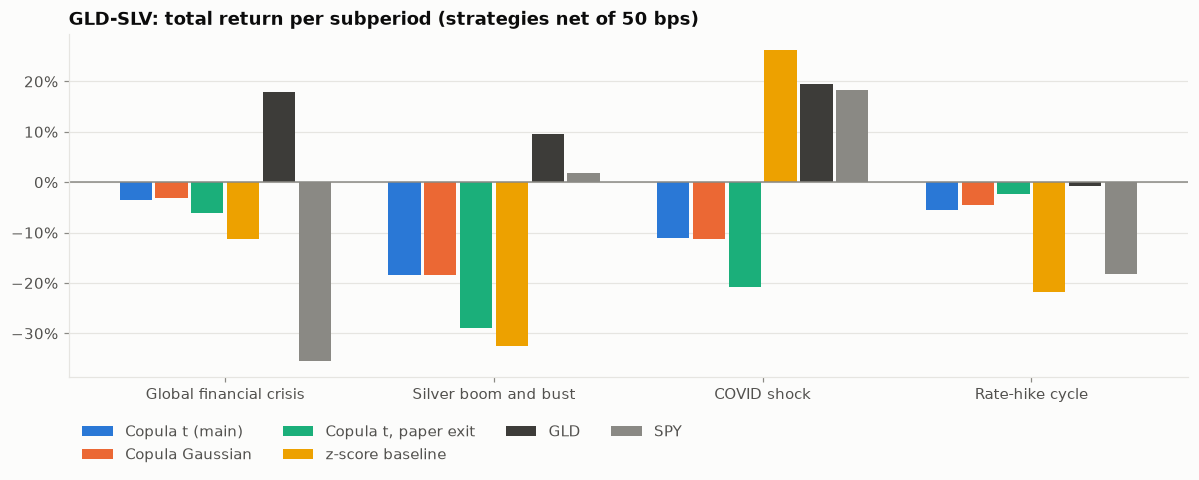

In [19]:
fig = plots.subperiod_returns(sub_main["total_return"][list(series)].drop(index="other"), PERIOD_LABELS,
                              f"{MAIN}: total return per subperiod (strategies net of 50 bps)")
plots.save(fig, "09_subperiod_returns");

**Across pairs.** Total return of the main copula spec and the z-score baseline per period, net of 50 bps.

In [20]:
rows = {}
for pair in PAIR_NAMES:
    for key, name in [("copula|t|probability", "Copula t (main)"), ("zscore|None|None", "z-score baseline")]:
        rows[(pair, name)] = analysis.subperiod_performance(load_returns(f"{pair}|{key}|50"), PERIODS)["total_return"]
pd.DataFrame(rows).T.rename(columns=PERIOD_LABELS)

Global financial crisis  Silver boom and bust  \
GLD-SLV  Copula t (main)                   -0.0350               -0.1840   
         z-score baseline                  -0.1134               -0.3256   
GDX-GDXJ Copula t (main)                       NaN               -0.1387   
         z-score baseline                      NaN               -0.1872   
XOM-CVX  Copula t (main)                   -0.1672               -0.0873   
         z-score baseline                   0.0384                0.0852   
KO-PEP   Copula t (main)                    0.0009               -0.0009   
         z-score baseline                   0.1875                0.0014   

                           COVID shock  Rate-hike cycle  All other days  
GLD-SLV  Copula t (main)       -0.1103          -0.0547         -0.6750  
         z-score baseline       0.2632          -0.2182          0.1780  
GDX-GDXJ Copula t (main)       -0.1469          -0.0979         -0.6424  
         z-score baseline       0.3029           0.0298          0.0807  
XOM-CVX  Copula t (main)       -0.1430          -0.0711         -0.3750  
         z-score baseline       0.3710           0.2490         -0.2171  
KO-PEP   Copula t (main)       -0.1136          -0.0509         -0.2586  
         z-score baseline      -0.0325           0.0054         -0.1607

**Does tail dependence rise in stress periods?** Median monthly t-copula parameters by period (each
month's fit uses the preceding 12 months, so a period's fits partly reflect the months before it).

In [21]:
pd.concat({pair: analysis.subperiod_copula(fits[pair], PERIODS).rename(index=PERIOD_LABELS)
           for pair in PAIR_NAMES}, names=["pair", "period"])

months  median_t_rho  median_t_nu  \
pair     period                                                        
GLD-SLV  Global financial crisis  19.0000        0.8677       7.9996   
         Silver boom and bust     12.0000        0.7968       6.7049   
         COVID shock              11.0000        0.7803       3.7243   
         Rate-hike cycle          12.0000        0.7909      17.4724   
         All other days          169.0000        0.8153      11.5097   
GDX-GDXJ Global financial crisis   0.0000           NaN          NaN   
         Silver boom and bust     12.0000        0.9267       6.2315   
         COVID shock              11.0000        0.9733      10.0806   
         Rate-hike cycle          12.0000        0.9684      14.9245   
         All other days          146.0000        0.9544       8.7950   
XOM-CVX  Global financial crisis  19.0000        0.8968       4.3918   
         Silver boom and bust     12.0000        0.8187       2.7686   
         COVID shock              11.0000        0.8883       3.2916   
         Rate-hike cycle          12.0000        0.9001       5.1763   
         All other days          169.0000        0.8266       4.2593   
KO-PEP   Global financial crisis  19.0000        0.6834       7.1406   
         Silver boom and bust     12.0000        0.5514       2.5211   
         COVID shock              11.0000        0.7706       2.0100   
         Rate-hike cycle          12.0000        0.7670       4.1838   
         All other days          169.0000        0.6919       5.6449   

                                  median_tail_dep  t_better_oos_share  
pair     period                                                        
GLD-SLV  Global financial crisis           0.4586              0.6316  
         Silver boom and bust              0.3759              0.4167  
         COVID shock                       0.4799              0.7273  
         Rate-hike cycle                   0.1760              0.1667  
         All other days                    0.2881              0.5858  
GDX-GDXJ Global financial crisis              NaN                 NaN  
         Silver boom and bust              0.6083              0.5833  
         COVID shock                       0.7041              0.9091  
         Rate-hike cycle                   0.6192              0.7500  
         All other days                    0.6362              0.5342  
XOM-CVX  Global financial crisis           0.6192              0.6842  
         Silver boom and bust              0.5757              0.6667  
         COVID shock                       0.6280              0.8182  
         Rate-hike cycle                   0.5820              0.8333  
         All other days                    0.5039              0.6746  
KO-PEP   Global financial crisis           0.2613              0.6842  
         Silver boom and bust              0.3867              0.8333  
         COVID shock                       0.5711              0.9091  
         Rate-hike cycle                   0.4553              0.7500  
         All other days                    0.3183              0.6568

## 7. Observations

Written from the tables above (run of 2026-10-24, significance tests added 2026-10-26). One historical
path per pair; with 4 pairs × 4 specs × 2 cost levels tested, individual p-values near 0.05 should be read
with multiple testing in mind.

**RQ1, dependence beyond Pearson.** Pearson correlation and the Kendall-implied correlation differ by at
most 0.03 in every pair, so linear correlation does not badly misstate the overall strength of
co-movement. The tails are where the structure shows: both legs fall into their own 5% tail on 2.2–3.8%
of days (vs 0.25% under independence), and the lower-tail share exceeds the upper-tail share in three of
four pairs over the full sample (GDX-GDXJ is the exception) and in all four out of sample. Joint crashes are more common than joint rallies, which no symmetric copula (Gaussian or t) can
represent.

**RQ2, t vs Gaussian.** The t-copula has the lower AIC in 59–98% of months and the higher
out-of-sample log-likelihood in 56.5–69% of months, with a positive total out-of-sample log-likelihood
gain in all four pairs, statistically significant in each (Newey-West p from < 0.001 to 0.03). Median ν is 4–10. Out of sample, the t-copula's predicted joint-tail frequency is
closer to the observed lower-tail frequency than the Gaussian's in every pair, but both still
under-predict lower-tail events and the t over-predicts upper-tail events in three of four pairs,
consistent with the asymmetry above. For GLD-SLV, ν sits near 100 (Gaussian-like) in several stretches
(e.g. 2016, 2023–2025), so the tail dependence is not stable over time.

**RQ3–RQ5, trading results.** None of the copula specifications earns a positive return on GLD-SLV, even
before costs (main spec: −2.4% a year gross, −7.9% net of 50 bps; Sharpe −0.37 / −0.99). Net of 50 bps,
all twelve copula runs across the four pairs have Sharpe ratios between −0.41 and −1.82. The z-score
baseline is roughly flat (net Sharpe −0.16 to +0.13) and buy-and-hold GLD returned about 10% a year over
the same period. The better-fitting t-copula trades only marginally better than the Gaussian copula: its net return is
higher in all four pairs by 0.4–1.6 percentage points a year, but the bootstrap interval of the
difference includes zero in three of four pairs (XOM-CVX is the exception), and both remain negative.

**Significance.** Before costs, no copula spec's mean return is distinguishable from zero at 5%
(Newey-West p ≥ 0.065); the GLD-SLV paper-exit Sharpe interval lies just below zero. After 50 bps, 11 of 12
copula runs have significantly negative mean returns (p < 0.02; KO-PEP with the paper exit is the
exception). The z-score baseline is never significant net of costs; before costs only XOM-CVX is
(p = 0.03). Buy-and-hold GLD is significantly positive (p = 0.004). So the evidence is not that copula
signals have no information gross of costs, it is that whatever they have is far smaller than a
realistic trading cost.

**Subperiods.** The copula strategy's losses are not a crisis effect. On GLD-SLV the main spec loses in all
four stress periods (−3.5% in the financial crisis, −18.4% in 2011, −11.0% in 2020, −5.5% in 2022), but
most of the loss accrues over the remaining ~14 years (−67.5%). Across pairs, the main spec's return is
negative in 18 of 19 pair-period cells (GDX-GDXJ has no data for 2007–09; the exception is KO-PEP in
2007–09 at +0.1%). The z-score baseline behaves differently: it gained 26–37% in the COVID period in three
of four pairs but lost 33% on GLD-SLV in 2011, when the gold/silver ratio moved far outside its prior
range. Tail dependence is highest in the COVID period for all four pairs (median λ 0.48–0.70), and the
t-copula's out-of-sample advantage is strongest there (better in 73–91% of months, vs 53–67% on other
days); in 2022 GLD-SLV looks almost Gaussian (median λ 0.18, t better in 2 of 12 months). Each stress
period holds only 11–19 monthly fits, so these are descriptive.

**Why, as far as the data shows.** In the main spec 95% of trades close on the probability-reversion rule
after 2.3 days on average: the signal is computed from one day's return, so the next day's return
almost always moves the conditional probabilities back across 0.5. Gross win rate is 46%, and the
average trade loses 17 bps before costs. The paper's quantile exit lengthens holding periods to about
8 days, but more than half of those trades end at the stop-loss and the average gross trade loses 52 bps.

These results do not replicate the paper's positive returns. Candidate explanations, none tested here:
different assets and period (mostly after the paper's 1990–2014 sample), no copula-based pair selection
(the paper picks the top pairs out of 4,950 by in-sample profitability), and a 20-day holding cap
instead of the paper's 120-day path.

## 8. Limitations

- One price path per pair, four pairs chosen ex ante; p-values are not adjusted for multiple testing.
- Returns are per $1 per leg, close-to-close, with no slippage model; short-selling of SLV/GDXJ/CVX/PEP is
  assumed available with no borrow fee.
- The paper's quantile rule occasionally produced a stop-loss at or above zero, or a take-profit at or
  below zero (25 of 635 trades across the four pairs); it was kept as specified rather than patched after
  seeing results.
- The t-copula ν estimate stops near 100 when the likelihood is flat; values there should be read as
  "no detectable tail dependence", not as an exact estimate.
- Free data: yfinance adjusted prices can be revised; the database stores the download timestamp.